In [108]:
#Data Analysis and Cleaning
import pandas as pd
import numpy as np

#Visulization
import matplotlib.pyplot as plt
import seaborn as sns

#For Ml
import sklearn

import warnings
warnings.filterwarnings('ignore')

## Step 1 Data Cleaning

In [123]:
data = pd.read_csv('housing (1).csv')

In [110]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [111]:
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [112]:
data.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [113]:
data.duplicated().sum()

np.int64(0)

### Outlier Handling

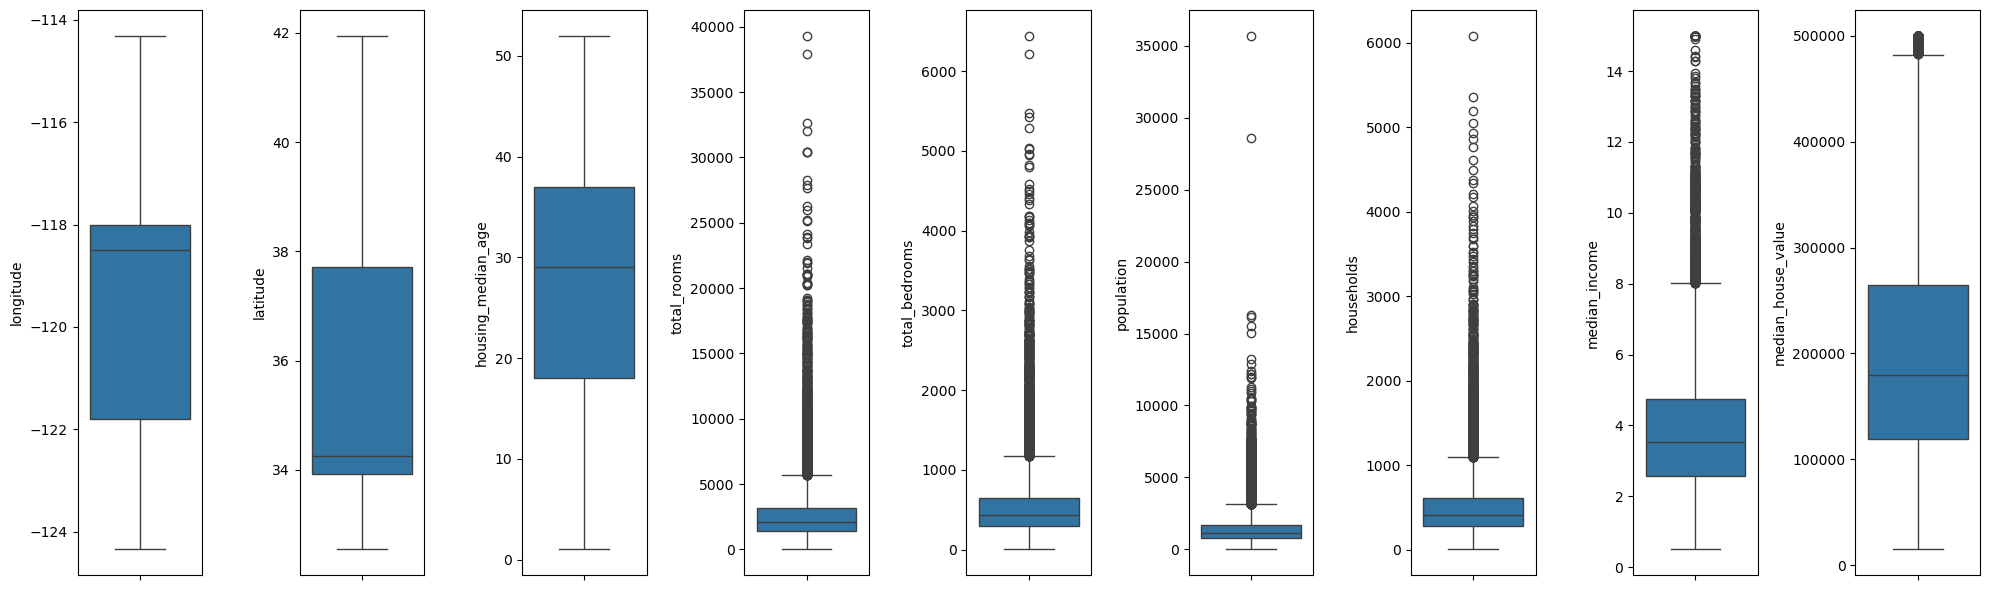

In [114]:
fig, axes = plt.subplots(nrows=1,ncols=len(data.select_dtypes('number').columns), figsize=(20,6))
for index, col in enumerate(data.select_dtypes('number').columns):
    sns.boxplot(data[col], ax=axes[index])
plt.tight_layout()

In [124]:
def cap_outlier(data):
    df = data.copy()
    numeric_df = df.select_dtypes('number')
    for column in numeric_df:
        q1 = np.percentile(data[column].dropna(), 25)
        q3 = np.percentile(data[column].dropna(), 75)
        iqr = q3-q1
        lwb = q1-1.5*iqr
        upb = q3+1.5*iqr
        numeric_df[column] = np.where(numeric_df[column] < lwb, lwb, numeric_df[column])
        numeric_df[column] = np.where(numeric_df[column] > upb, upb, numeric_df[column])
    return numeric_df  

In [125]:
free_outler_df = cap_outlier(data)
free_outler_df['ocean_proximity'] = data['ocean_proximity']

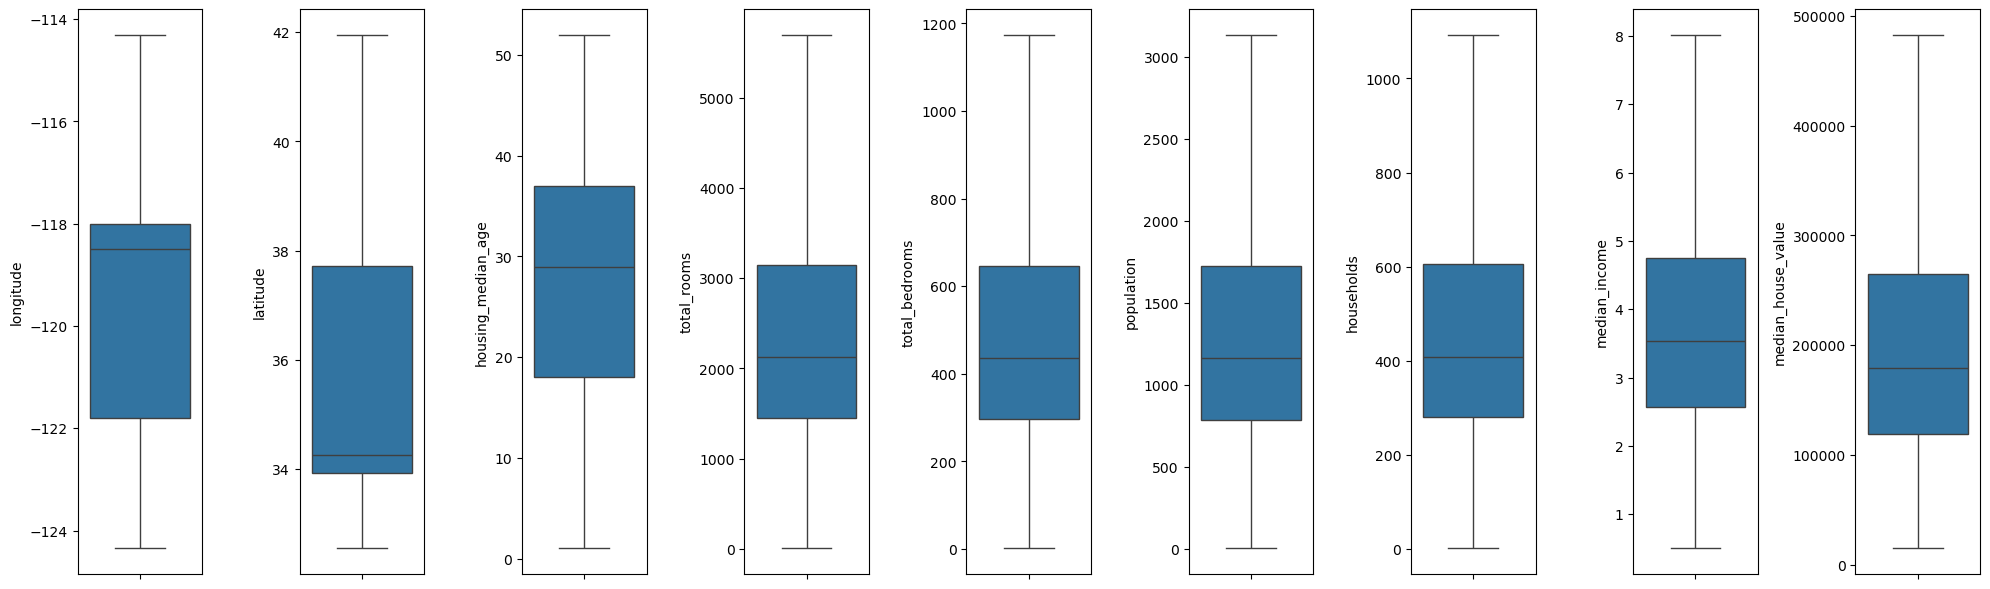

In [11]:
fig, axes = plt.subplots(nrows=1,ncols=len(free_outler_df.select_dtypes('number').columns), figsize=(20,6))
for index, col in enumerate(free_outler_df.select_dtypes('number').columns):
    sns.boxplot(free_outler_df[col], ax=axes[index])
plt.tight_layout()

In [126]:
free_outler_df.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [127]:
free_outler_df.fillna(free_outler_df.total_bedrooms.mean(), inplace=True)

In [128]:
free_outler_df.isna().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

# Step 2: Splitting Data

In [249]:
X = free_outler_df.drop(columns='median_house_value', axis=1)
y = free_outler_df.median_house_value

In [250]:
from sklearn.model_selection import train_test_split

In [251]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)

In [252]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((14448, 9), (6192, 9), (14448,), (6192,))

# Step 3: Data Transformation

## Encoding

#### One Hot Encoding

In [253]:
data.ocean_proximity.unique()

array(['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND'],
      dtype=object)

In [254]:
from sklearn.preprocessing import OneHotEncoder

In [255]:
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

In [256]:
ohe.set_output(transform='pandas')
train_encoded = ohe.fit_transform(X_train[['ocean_proximity']])
test_encoded = ohe.transform(X_test[['ocean_proximity']])

X_train = pd.concat([X_train.drop(columns=['ocean_proximity'], axis=1), train_encoded], axis=1)
X_test = pd.concat([X_test.drop(columns=['ocean_proximity'], axis=1), test_encoded], axis=1)

### Scaling

In [257]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [258]:
mms = MinMaxScaler()

In [259]:
mms.set_output(transform='pandas')
X_train = mms.fit_transform(X_train)
X_test = mms.transform(X_test)

# Step 4: Feeding Models

## Linear Regression Model

In [260]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

#### Prediction of Linear Regression

In [261]:
lr_y_train_pred = lr.predict(X_train)
lr_y_test_pred = lr.predict(X_test)

#### Linear Regression Model Evaluation

In [262]:
from sklearn.metrics import r2_score, mean_squared_error

Models_scores = pd.DataFrame({
    'Model_Name': ['Linear Regression'], 
    'R2_Score_Training': [r2_score(y_train, lr_y_train_pred)], 
    'R2_Score_Testing': [r2_score(y_test, lr_y_test_pred)]
})
Models_scores

,Model_Name,R2_Score_Training,R2_Score_Testing
0,Linear Regression,0.671048,0.649574


## Polynomial Regression

In [263]:
from sklearn.preprocessing import PolynomialFeatures

In [264]:
plr = LinearRegression()
pr = PolynomialFeatures(degree=3)
poly_x_train = pr.fit_transform(X_train)
poly_x_test = pr.transform(X_test)
plr.fit(poly_x_train, y_train)

LinearRegression()

#### Prediction of Polynomial Regression

In [265]:
plr_y_train_pred = plr.predict(poly_x_train)
plr_y_test_pred = plr.predict(poly_x_test)

#### Linear Regression Model Evaluation

In [266]:
Models_scores.loc[1] = ['Polynomial Regression', r2_score(y_train,plr_y_train_pred), r2_score(y_test,plr_y_test_pred)]
Models_scores

,Model_Name,R2_Score_Training,R2_Score_Testing
0,Linear Regression,0.671048,0.649574
1,Polynomial Regression,0.787283,0.674441


## Lasso and Ridge With Linear Regression

In [267]:
from sklearn.linear_model import RidgeCV, LassoCV

In [268]:
#for lasso
alphas = [1.0, 0.01, 1.0, 10.0, 100.0]
lc = LassoCV(alphas=alphas, cv=5)
lc.fit(X_train,y_train)

LassoCV(alphas=[1.0, 0.01, 1.0, 10.0, 100.0], cv=5)

In [269]:
#for Ridge
rc = RidgeCV(alphas=alphas, cv=5)
rc.fit(X_train,y_train)

RidgeCV(alphas=[1.0, 0.01, 1.0, 10.0, 100.0], cv=5)

#### Prediction

In [270]:
#for lasso
#for training
lc_y_train_pred = lc.predict(X_train)
#for testing
lc_y_test_pred = lc.predict(X_test)
lc.alpha_

np.float64(0.01)

In [271]:
#for ridge
#for training
rc_y_train_pred = rc.predict(X_train)
#for testing
rc_y_test_pred = rc.predict(X_test)
rc.alpha_

np.float64(0.01)

#### Lasso Model Evaluation

In [272]:
Models_scores.loc[2] = ['Lasso Regression', r2_score(y_train, lc_y_train_pred), r2_score(y_test, lc_y_test_pred)]
Models_scores.loc[3] = ['Ridge Regression', r2_score(y_train, lc_y_train_pred), r2_score(y_test, lc_y_test_pred)]
Models_scores

,Model_Name,R2_Score_Training,R2_Score_Testing
0,Linear Regression,0.671048,0.649574
1,Polynomial Regression,0.787283,0.674441
2,Lasso Regression,0.671048,0.649574
3,Ridge Regression,0.671048,0.649574


## Lasso and Ridge With Polynomial Feature

In [273]:
#for lasso
alphas = [0.01, 0.1, 1.0, 10.0, 100.0]
prl = PolynomialFeatures(degree=2)
pl_x_train = pr.fit_transform(X_train)
pl_x_test = pr.transform(X_test)
plc = LassoCV(alphas=alphas, cv=5)
plc.fit(pl_x_train,y_train)

LassoCV(alphas=[0.01, 0.1, 1.0, 10.0, 100.0], cv=5)

In [274]:
#for ridge
prc = RidgeCV(alphas=alphas, cv=5)
prc.fit(pl_x_train,y_train)

RidgeCV(alphas=[0.01, 0.1, 1.0, 10.0, 100.0], cv=5)

#### prediction

In [275]:
#for lasso
#for training
plc_y_train_pred = plc.predict(pl_x_train)
#for testing
plc_y_test_pred = plc.predict(pl_x_test)

#for ridge
#for training
prc_y_train_pred = prc.predict(pl_x_train)
#for testing
prc_y_test_pred = prc.predict(pl_x_test)

#### Lasso and RIdge With Polynomial Feature Model Evaluation

In [276]:
Models_scores.loc[4] = ['Lasso Regression With Polynomial Feature', r2_score(y_train, plc_y_train_pred), r2_score(y_test, plc_y_test_pred)]
Models_scores.loc[5] = ['Ridge Regression With Polynomial Feature', r2_score(y_train, plc_y_train_pred), r2_score(y_test, plc_y_test_pred)]
Models_scores

,Model_Name,R2_Score_Training,R2_Score_Testing
0,Linear Regression,0.671048,0.649574
1,Polynomial Regression,0.787283,0.674441
2,Lasso Regression,0.671048,0.649574
3,Ridge Regression,0.671048,0.649574
4,Lasso Regression With Polynomial Feature,0.772067,0.746864
5,Ridge Regression With Polynomial Feature,0.772067,0.746864


## SVM (Support Vector Machine)

In [277]:
from sklearn.svm import SVR

In [278]:
svr = SVR(kernel='poly')
svr.fit(X_train,y_train)

SVR(kernel='poly')

In [279]:
svr_y_train_pred = svr.predict(X_train)
svr_y_test_pred = svr.predict(X_test)

In [280]:
r2_score(y_train,svr_y_train_pred), r2_score(y_test,svr_y_test_pred)

(0.035765595878908596, 0.031989818305662276)

#### SVR model Evaluation

In [281]:
Models_scores.loc[6] = ['SVR(Support Vector Rwgression)', r2_score(y_train,svr_y_train_pred), r2_score(y_test,svr_y_test_pred)]
Models_scores

,Model_Name,R2_Score_Training,R2_Score_Testing
0,Linear Regression,0.671048,0.649574
1,Polynomial Regression,0.787283,0.674441
2,Lasso Regression,0.671048,0.649574
3,Ridge Regression,0.671048,0.649574
4,Lasso Regression With Polynomial Feature,0.772067,0.746864
5,Ridge Regression With Polynomial Feature,0.772067,0.746864
6,SVR(Support Vector Rwgression),0.035766,0.031990


## Decission Tree

In [282]:
from sklearn.tree import DecisionTreeRegressor

In [283]:
DX = data.drop('median_house_value', axis=1)
dy = data.median_house_value
DX = (pd.concat([DX, pd.get_dummies(DX.ocean_proximity, dtype=int)], axis=1)).drop('ocean_proximity', axis=1)

In [284]:
m = MinMaxScaler()
m.set_output(transform='pandas')
msx = m.fit_transform(DX)
msx.head(3)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,0.211155,0.567481,0.784314,0.022331,0.019863,0.008941,0.020556,0.539668,0.0,0.0,0.0,1.0,0.0
1,0.212151,0.565356,0.392157,0.180503,0.171477,0.067210,0.186976,0.538027,0.0,0.0,0.0,1.0,0.0
2,0.210159,0.564293,1.000000,0.037260,0.029330,0.013818,0.028943,0.466028,0.0,0.0,0.0,1.0,0.0


In [285]:
from sklearn.model_selection import train_test_split
dx_train,dx_test,dy_train,dy_test = train_test_split(msx,dy, test_size=0.2, random_state=42)

In [286]:
dtr = DecisionTreeRegressor()

In [287]:
dtr.fit(dx_train,dy_train)

DecisionTreeRegressor()

In [288]:
dtr_y_train_Pred = dtr.predict(dx_train)
dtr_y_test_Pred = dtr.predict(dx_test)

In [289]:
Models_scores.loc[7] = ['Decission Tree Regression', r2_score(dy_train,dtr_y_train_Pred), r2_score(dy_test,dtr_y_test_Pred)]
Models_scores

,Model_Name,R2_Score_Training,R2_Score_Testing
0,Linear Regression,0.671048,0.649574
1,Polynomial Regression,0.787283,0.674441
2,Lasso Regression,0.671048,0.649574
3,Ridge Regression,0.671048,0.649574
4,Lasso Regression With Polynomial Feature,0.772067,0.746864
5,Ridge Regression With Polynomial Feature,0.772067,0.746864
6,SVR(Support Vector Rwgression),0.035766,0.031990
7,Decission Tree Regression,1.000000,0.639359


# Conclusion

### our Best Fit Model is _*Ridge & Lasso Regression With Polynomial Feature*_ Model 